# Model Inference Notebook

This notebook load a computer vision model using PyTorch.  
It loads the dataset, initializes the model, trains it, visualizes metrics,  
and evaluates it on a validation set.

The workflow:
1. Import libraries
2. Load Hyperparameters and Initialize the Model
3. Load Test Images
4. Define Class Names and Load Dataset Statistics
5. Preprocess Images and Build a Batch
6. Run Inference and Print Top-1 Predictions
7. Visualize Images with Top-1 Predictions
8. Visualize Images with Top-3 Predictions
9. Grad-CAM

## Step 1 – Import libraries
We start by importing all required packages and modules for training and evaluation.

In [1]:
import os
import json
import time
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
# Core modules imports
from core.config import Config
from core.trainer import Trainer
from core.predictor import Predictor
from core.checkpoint import CheckpointManager
from core.visualizer import Visualizer
from core.model_base import Model
from core.metrics import confusion_matrix_torch

# Data and Model imports
from data_loader import get_torchvision_dataset

from core.gradcam import GradCAM, overlay_heatmap
import cv2

## Step 2 – Load Hyperparameters and Initialize the Model
We load the metadata saved during training, extract the
model parameters, then rebuild and load the trained model.

In [2]:
# Use the run_id from the training you want to load
run_id = 'resnet18_cifar10_2026-11-09_15-47-30'

In [3]:
meta_path = os.path.join(f"experiments/{run_id}", "meta.json")
with open(meta_path, "r", encoding="utf-8") as f:
    meta = json.load(f)

image_size = meta['data']['image_size']

config = Config.from_dict(meta)

In [4]:
model = Model(config)

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Log model specifics like name and total parameters.
print(f"  Model        : {model.name}")
print(f"  Parameters    : {sum(p.numel() for p in model.parameters()):,}")
trainer = Trainer.from_config(
    model=model,
    config=config,
    device=device,
)

# Setup the CheckpointManager to save and load training state.
checkpoint = CheckpointManager(
    model=model,
    optimizer=trainer.optimizer,
    run_id=trainer.run_id,
)

# Configure the trainer to save the best model checkpoint.
if config.experiment.save_checkpoints:
    trainer.on_best_model = checkpoint.save

# Log the unique run identifier.
print(f"  Run ID        : {trainer.run_id}")

# Initialize the Predictor and Visualizer components.
predictor = Predictor(model=model, device=device)
visualizer = Visualizer()
RESUME = True
if RESUME:
    # Load training state if RESUME is True and a checkpoint exists.
    # state = checkpoint.load_latest(load_optimizer=True)
    state = checkpoint.load_best(monitor=config.metrics.monitor_metric, mode=config.metrics.monitor_mode, load_optimizer=True)

  Model        : resnet18
  Parameters    : 11,173,962
  Run ID        : resnet18_cifar10_2026-11-09_15-47-30
Loaded checkpoint: model_epoch-10_Top_1_Accuracy-0.8665.pt (epoch 10, Top_1_Accuracy 0.8665)


In [6]:
train_loader, val_loader = get_torchvision_dataset(
    dataset_name=config.experiment.dataset_name, 
    root_dir='./data', 
    batch_size=config.training.batch_size,
    image_size=config.data.image_size,
    use_computed_stats=True
)

dataset_name = config.experiment.dataset_name
num_classes = config.model.num_classes
class_names = train_loader.dataset.classes

[Stats] Loading existing stats from ./data\CIFAR10\stats.json
[Stats] CIFAR10 mean=[0.4913996458053589, 0.48215851187705994, 0.4465310275554657], std=[0.2470322549343109, 0.24348489940166473, 0.2615877091884613]
Loaded dataset 'CIFAR10' from './data\CIFAR10'.


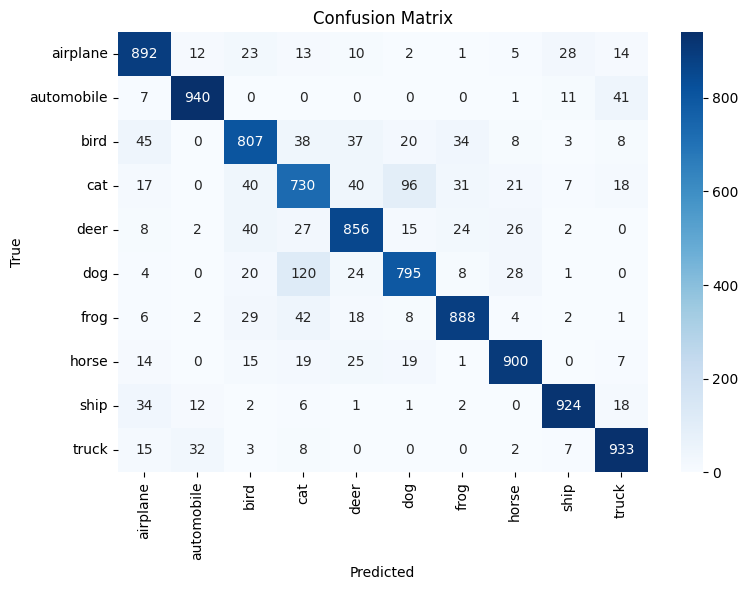

In [7]:
y, logits = trainer.collect_predictions(val_loader)
cm = confusion_matrix_torch(y, logits, num_classes)
visualizer.plot_confusion_matrix(cm, class_names, run_id=model.run_id, save=False)

## Step 3 - Load images
We load all images inside a folder, filtering by image
extensions. Each image is stored as a PIL Image object.

In [8]:
folder = "data/example/train/cat"

images = []
for filename in os.listdir(folder):
    if filename.lower().endswith((".png", ".jpg", ".jpeg")):
        path = os.path.join(folder, filename)
        img = Image.open(path)
        images.append(img)

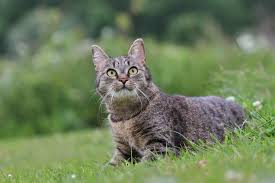

In [9]:
# Display the first loaded image
images[0]

## Step 4 – Load Dataset Statistics
We need class names to interpret predictions,
and dataset mean/std to normalize images consistently
with model training.

In [10]:
# Load normalization statistics from training
stats_path = os.path.join(f"data/{dataset_name}", "stats.json")
with open(stats_path, "r", encoding="utf-8") as f:
    stats = json.load(f)

mean = stats['mean']
std = stats['std']

In [11]:
# Define the preprocessing transform
transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

## Step 5 – Preprocess Images and Build a Batch
Each image is converted to RGB, transformed, normalized,
and added into a single PyTorch batch tensor.

In [12]:
batch = []
for img in images:
    # img = img.convert("RGB")
    tensor = transform(img)
    batch.append(tensor)

# Stack into a batch and move to GPU
batch = torch.stack(batch).to('cuda')

## Step 6 – Run Inference and Print Top-1 Predictions
The model outputs probabilities for each class. We take
the predicted class (top-1) and print confidence scores.

In [13]:
outputs = model(batch)

probs = torch.softmax(outputs, dim=1)

top1 = torch.argmax(probs, dim=1)

In [14]:
probs = predictor.predict(batch, return_probs=True)

top1 = torch.argmax(probs, dim=1)

In [15]:
for i, img in enumerate(images):
    predicted_class = class_names[top1[i].item()]
    confidence = probs[i][top1[i]].item()

    print(f"Image {i}: {predicted_class} ({confidence:.2f})")

Image 0: deer (0.91)
Image 1: deer (0.83)
Image 2: cat (0.60)
Image 3: cat (0.83)
Image 4: cat (0.50)
Image 5: cat (0.58)
Image 6: deer (0.50)
Image 7: cat (0.58)


## Step 7 – Visualize Images with Top-1 Predictions

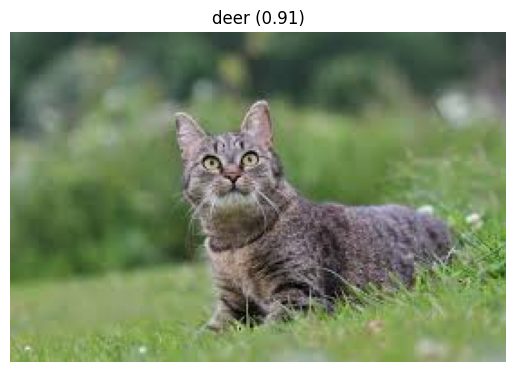

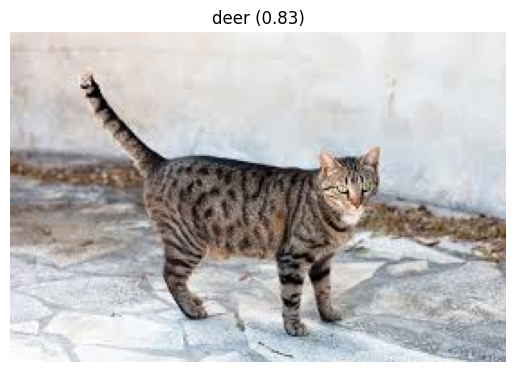

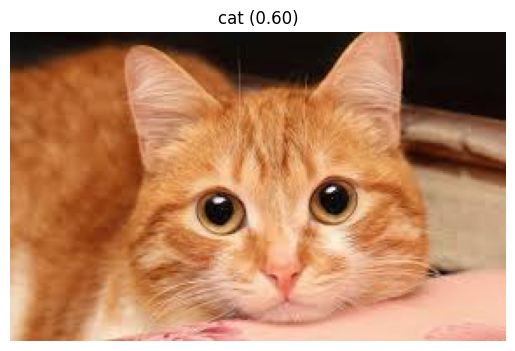

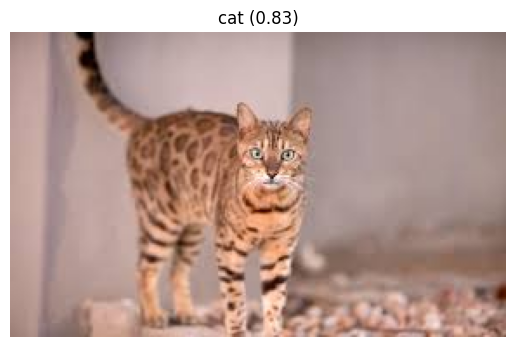

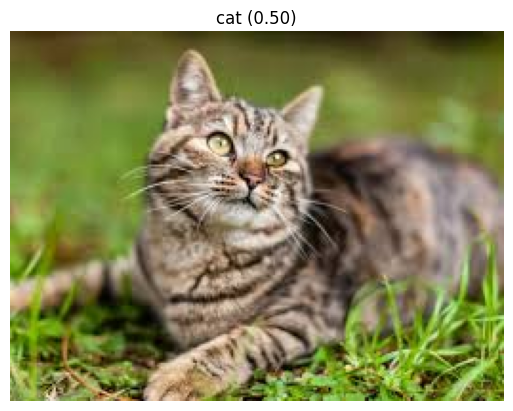

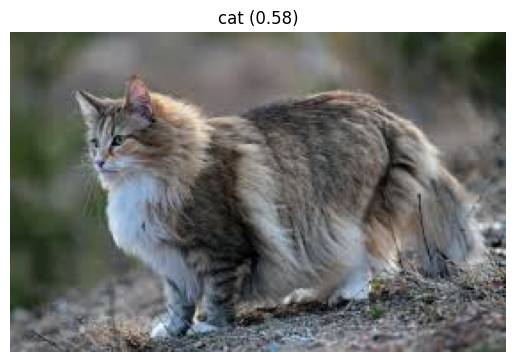

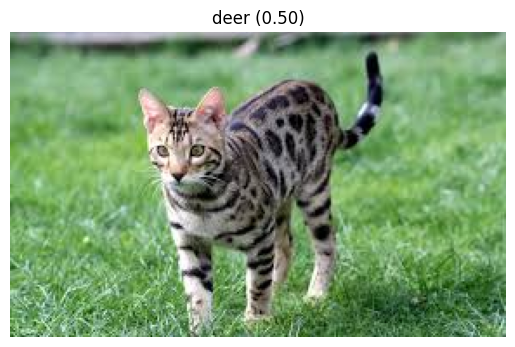

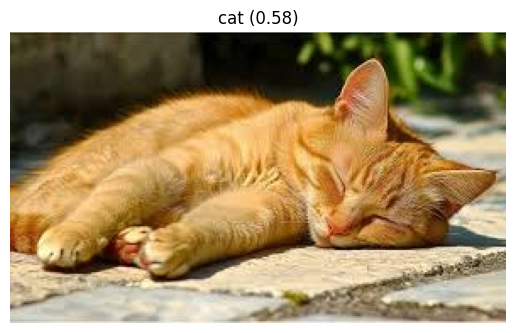

In [16]:
for i, img in enumerate(images):
    plt.imshow(img)
    plt.title(f"{class_names[top1[i].item()]} ({probs[i][top1[i]].item():.2f})")
    plt.axis("off")
    plt.show()

## Step 8 – Visualize Images with Top-3 Predictions
We display the three most likely classes for each image,
which helps assess model confidence and uncertainty.

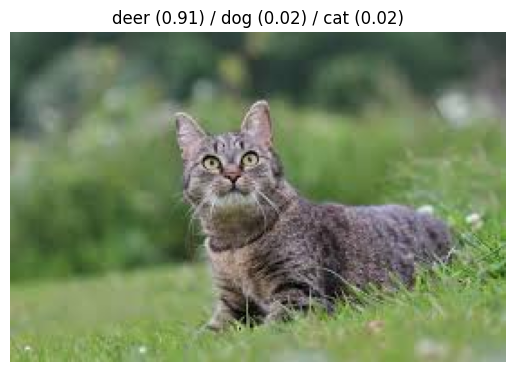

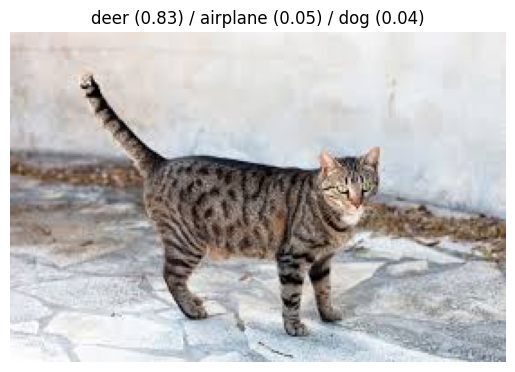

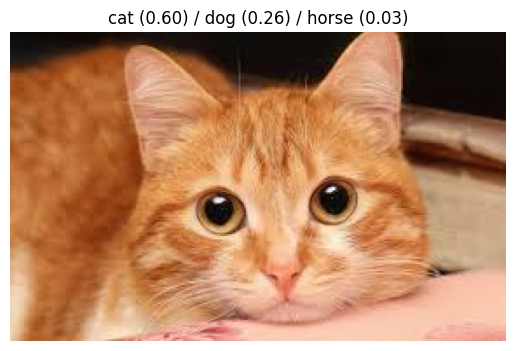

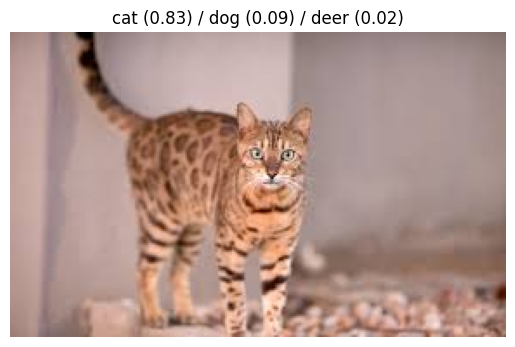

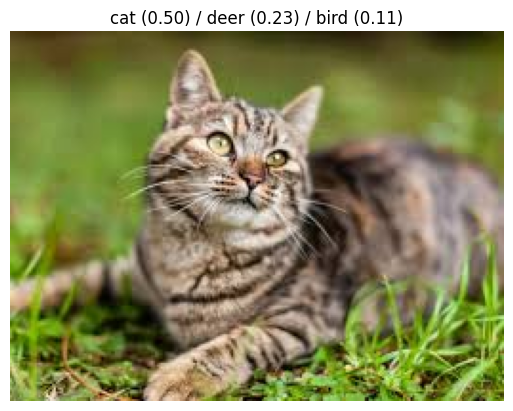

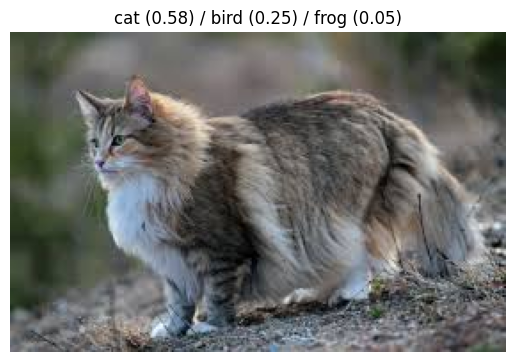

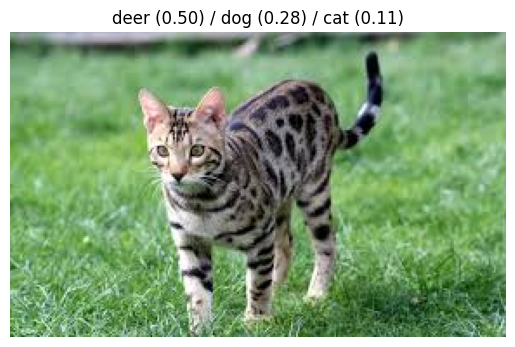

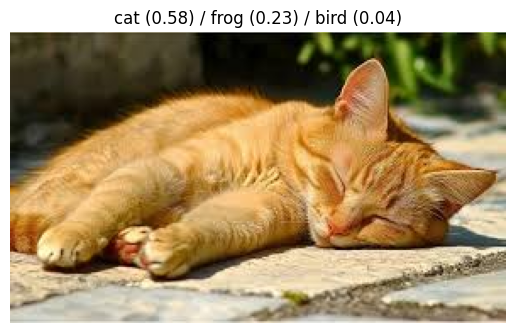

In [17]:
top3_probs, top3_indices = probs.topk(3, dim=1)

for i, img in enumerate(images):
    labels = [
        f"{class_names[top3_indices[i][k].item()]} ({top3_probs[i][k].item():.2f})"
        for k in range(3)
    ]
    title = " / ".join(labels)

    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.show()


## Step 9 - Grad-CAM

In [18]:
model.net.backbone.get_target_layer()

Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)

In [19]:
# Retrieve the target layer
target_layer = model.net.backbone.get_target_layer()

# Initialize Grad-CAM
grad_cam = GradCAM(model=model, target_layer=target_layer)

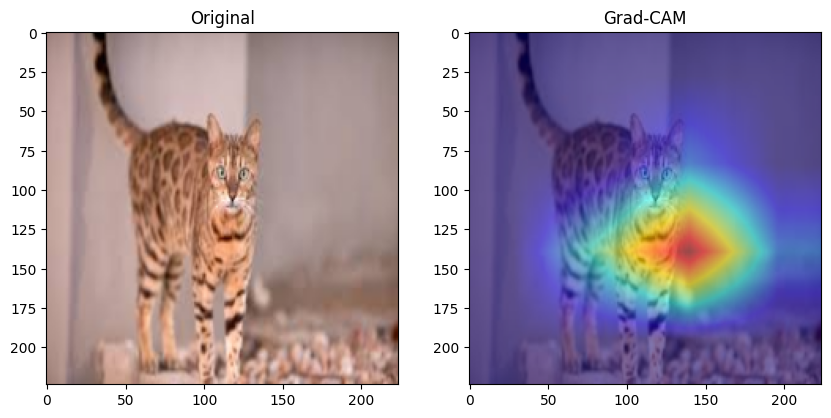

In [28]:
# Load an image
img_path = "data/example/train/cat/cat4.jpg"
pil_img = Image.open(img_path).convert('RGB')

# Preprocessing (Same as during training!)
preprocess = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])
input_tensor = preprocess(pil_img).unsqueeze(0).to("cuda") # (1, 3, 32, 32)

# Generate the heatmap
# target_class=None -> automatically uses the most probable predicted class
# target_class=3 -> forces the explanation for class "cat" (index 3 for example)
mask = grad_cam.generate(input_tensor, target_class=None)

# Visualization
# Load the original image for overlay
original_img = cv2.imread(img_path)
original_img = cv2.resize(original_img, (224, 224)) # Larger for better visibility

# Resize the mask to 224x224 for nicer displayvvv
mask_resized = cv2.resize(mask, (224, 224))

heatmap_img = overlay_heatmap(img_path, mask_resized)

# Matplotlib display
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Original")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB))
plt.title("Grad-CAM")
plt.show()